# 01 · Learning the Owner's Decision Profile: One Owner, Many Decision Types, and a Specifier in Between

**Juan Antonio Sainz Gálvez** · Applied AI & ML, Conestoga College · [Portfolio home](../README.md)

<a href="https://colab.research.google.com/github/antoniosg2025-stack/applied-ai-research-portfolio/blob/main/notebooks/01_owner_decision_profile.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

> **Main thesis question.** How can LLM agents learn, from an owner's approvals, rejections and corrections, a **decision profile** grounded in the owner's personality and situation (constraints and strengths: economic, skills, cognitive, family and business), so that they **minimize the gap between the agent's decision and the decision the owner would have made**, across different types of decisions, as the owner evolves, and when other users operate the system on the owner's behalf, **deferring to the owner** whenever that gap is likely to be large?
>
> **Error, in this portfolio, always means:** the agent decided differently from how the owner would have decided.

**This case:** the framework for the whole portfolio. My businesses are run by LLM agents and a few people (specifiers). Every action needs my approval, so I am the bottleneck. This notebook formalizes what the agent must learn: not one rule, but how I decide for each type of decision, how that changes when my situation changes, and what happens when another person approves on my behalf.


In [1]:
# Visual style used across the portfolio
import matplotlib.pyplot as plt
import matplotlib as mpl
from matplotlib.patches import FancyBboxPatch

PALETTE = {"navy": "#1B2A41", "teal": "#0F7C80", "gold": "#E0A526",
           "coral": "#D9534F", "sky": "#5BA4CF", "grey": "#8A94A6", "light": "#F4F6F9"}
POLICY_COLORS = [PALETTE["grey"], PALETTE["sky"], PALETTE["gold"], PALETTE["teal"], PALETTE["coral"]]

mpl.rcParams.update({
    "figure.dpi": 110, "figure.facecolor": "white", "axes.facecolor": "white",
    "axes.edgecolor": "#D5DAE1", "axes.grid": True, "grid.color": "#E9ECF1", "grid.linewidth": 0.8,
    "axes.spines.top": False, "axes.spines.right": False, "axes.axisbelow": True,
    "axes.titlesize": 14, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.labelsize": 11, "axes.labelcolor": "#3A4556", "xtick.color": "#5A6576", "ytick.color": "#5A6576",
    "legend.frameon": False, "font.family": "DejaVu Sans",
    "axes.prop_cycle": mpl.cycler(color=POLICY_COLORS),
})


def box(ax, xy, w, h, text, color, fontsize=10, text_color="white"):
    """Rounded box for infographics."""
    ax.add_patch(FancyBboxPatch(xy, w, h, boxstyle="round,pad=0.02,rounding_size=0.08", fc=color, ec="none"))
    if text:
        ax.text(xy[0] + w / 2, xy[1] + h / 2, text, ha="center", va="center",
                color=text_color, fontsize=fontsize, fontweight="bold")


def arrow(ax, start, end, color="#8A94A6"):
    ax.annotate("", xy=end, xytext=start,
                arrowprops=dict(arrowstyle="-|>", color=color, lw=2, shrinkA=4, shrinkB=4))


def thesis_card(case, profile, decision, signal):
    """The same infographic opens every notebook: owner profile -> agent decision model -> act or ask."""
    fig, ax = plt.subplots(figsize=(12, 4.6)); ax.set_xlim(0, 12); ax.set_ylim(0, 4.6); ax.axis("off")
    box(ax, (0.1, 0.35), 4.0, 3.5, "", PALETTE["navy"])
    ax.text(2.1, 3.45, "OWNER PROFILE", ha="center", color="white", fontsize=11, fontweight="bold")
    for i, item in enumerate(profile[:5]):
        ax.text(0.3, 2.9 - i * 0.5, "• " + item, color="white", fontsize=9, va="center")
    box(ax, (4.55, 1.55), 3.2, 1.6, "Agent learns how\nthe owner decides:\n" + decision, PALETTE["teal"], fontsize=10.5)
    box(ax, (4.55, 0.35), 3.2, 0.9, "learns from:\n" + signal, PALETTE["sky"], fontsize=9.5)
    box(ax, (8.3, 2.5), 3.5, 1.1, "Likely the same decision\nas the owner  ->  ACT", PALETTE["gold"], fontsize=10.5)
    box(ax, (8.3, 0.75), 3.5, 1.1, "Likely a different decision\n->  ASK THE OWNER", PALETTE["coral"], fontsize=10.5)
    arrow(ax, (4.1, 2.35), (4.5, 2.35)); arrow(ax, (7.8, 2.6), (8.25, 3.0)); arrow(ax, (7.8, 2.1), (8.25, 1.3))
    ax.set_title("Case: " + case, pad=4)
    plt.show()


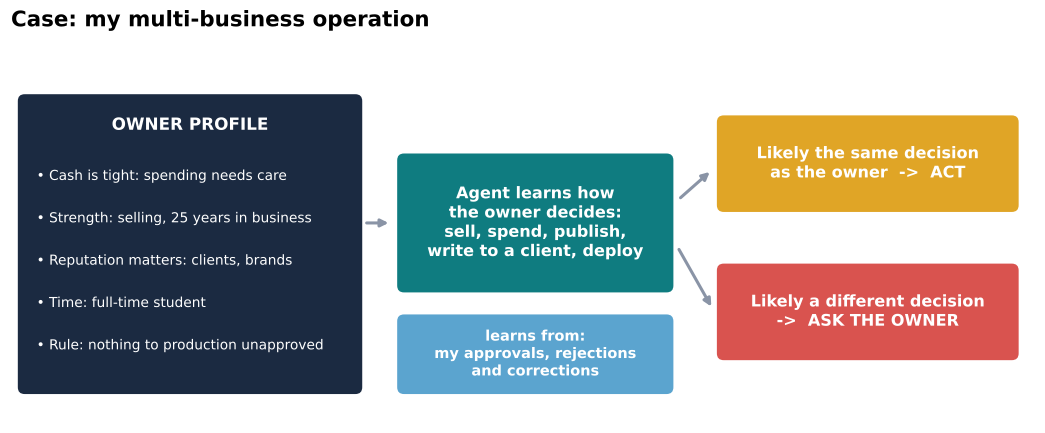

In [2]:
thesis_card("my multi-business operation",
            ["Cash is tight: spending needs care", "Strength: selling, 25 years in business",
             "Reputation matters: clients, brands", "Time: full-time student",
             "Rule: nothing to production unapproved"],
            "sell, spend, publish,\nwrite to a client, deploy",
            "my approvals, rejections\nand corrections")

## 1. The problem in one paragraph

When I gave my agent rules, it followed them **with me**. When a specifier started using the same system, some rules were applied and others were not, and when the agent was unsure it simply did not decide. I had to specify everything again for each person, test it in the sandbox, and publish it again. The rules were never the real object: the real object is **how I decide**, which depends on my situation (cash, time, skills, reputation) and changes with the type of decision. A sale I approve almost always; spending I approve only when it is small and reversible; writing to a client I approve only when the tone and facts are right.

## 2. Literature: what we know and what is missing

| Research line | Key result | What it gives this thesis |
|---|---|---|
| Value alignment as a game (CIRL) [1] | The agent is rewarded by the human's reward but does not know it; optimal behaviour includes asking and learning actively | The formal frame: the agent's objective *is* the owner's decision function, learned through interaction |
| Personalized RLHF (VPL) [2] | Standard RLHF **averages over individual differences**, producing inaccurate rewards for individuals; a user-specific latent fixes it and measures uncertainty | A single "average" policy is wrong for any particular owner; uncertainty tells the agent when to ask |
| Individual feedback linked to profiles (PRISM) [3] | 1,500 participants from 75 countries; preferences differ by person and context | Profiles must be individual and contextual, not demographic |
| Agents of 1,000 real people [4] | Agents built from 2-hour interviews reproduce people's survey answers 85% as accurately as people reproduce themselves two weeks later, better than agents given demographic descriptions | Rich personal context beats generic descriptions; a person is not consistent with themselves either (our noise floor) |
| Learning to defer [5, 6] | Learn a classifier *and* a rejector that decides when to pass the case to the expert | The "ask the owner" decision is learnable, not a fixed threshold |
| Bounded rationality and scarcity [7, 8] | Real decisions are shaped by limited time, information and resources; scarcity changes what people choose | The owner's constraints are part of the decision function, so the profile must encode the situation |
| Concept drift [9] | Models must adapt when the data-generating process changes | The owner evolves (debts paid, new business), so the profile must forget |

**Gap.** Personalization research learns a user's *preferences over outputs* (text, recommendations). Agents that operate a business must learn a user's *decisions over actions* with very different stakes per decision type, and must keep the owner's intent when **someone else** gives the approvals.


## 3. Model

Each decision *i* has a type *k* (sell, spend, publish, client message, deploy) and a context vector **x** (amount, reversibility, novelty, brand risk, urgency, evidence quality). The owner approves if

**owner(x, k) = 1[ w_k · x + b_k + ε > 0 ]**,

where **w_k, b_k** is the owner's profile for type *k* (derived from his situation) and ε is the owner's own inconsistency. The agent sees the context, predicts p = P(owner approves), and either **acts** (follows its prediction) or **asks**. Every answer becomes a training label.

**Error = the agent acted and the owner would have decided differently.**


In [3]:
import numpy as np
import pandas as pd
from sklearn.linear_model import LogisticRegression

FEATURES = ["amount", "reversible", "novelty", "brand_risk", "urgency", "evidence"]
TYPES = ["sell", "spend", "publish", "client_msg", "deploy"]

# The owner's profile per decision type (hidden from the agent). Signs follow the stated situation:
# selling is a strength (approve broadly), cash is tight (amount hurts spending), reputation matters
# (brand risk hurts publishing and client messages), production changes must be reversible.
OWNER = {
    "sell":       dict(w=[ 0.3, 0.2, -0.2, -0.8, 0.4, 0.5], b=2.2),
    "spend":      dict(w=[-2.6, 1.4, -0.6, -0.2, 0.3, 0.9], b=0.2),
    "publish":    dict(w=[ 0.0, 0.6,  0.4, -2.4, 0.8, 0.9], b=0.3),
    "client_msg": dict(w=[-0.3, 0.2, -0.9, -2.0, 0.2, 1.6], b=-0.2),
    "deploy":     dict(w=[-0.4, 2.4, -1.2, -0.6, 0.2, 1.2], b=-0.6),
}
# A specifier with a different situation: more permissive with money and brand, less with novelty
SPECIFIER = {k: dict(w=list(np.array(v["w"]) * [0.3, 0.5, 1.2, 0.4, 1.0, 0.6]), b=v["b"] + 0.9) for k, v in OWNER.items()}
NOISE = 0.35   # the owner's own inconsistency

def decide(profile, k, x, rng):
    z = np.dot(profile[k]["w"], x) + profile[k]["b"] + rng.normal(0, NOISE)
    return int(z > 0)

def stream(rng, days=120, per_day=40):
    for d in range(days):
        for _ in range(per_day):
            yield d, TYPES[rng.integers(len(TYPES))], rng.normal(size=len(FEATURES))

W = pd.DataFrame({k: OWNER[k]["w"] for k in TYPES}, index=FEATURES).T
print("Owner profile (hidden weights) by decision type:"); W.round(1)

Owner profile (hidden weights) by decision type:


,amount,reversible,novelty,brand_risk,urgency,evidence
sell,0.3,0.2,-0.2,-0.8,0.4,0.5
spend,-2.6,1.4,-0.6,-0.2,0.3,0.9
publish,0.0,0.6,0.4,-2.4,0.8,0.9
client_msg,-0.3,0.2,-0.9,-2.0,0.2,1.6
deploy,-0.4,2.4,-1.2,-0.6,0.2,1.2


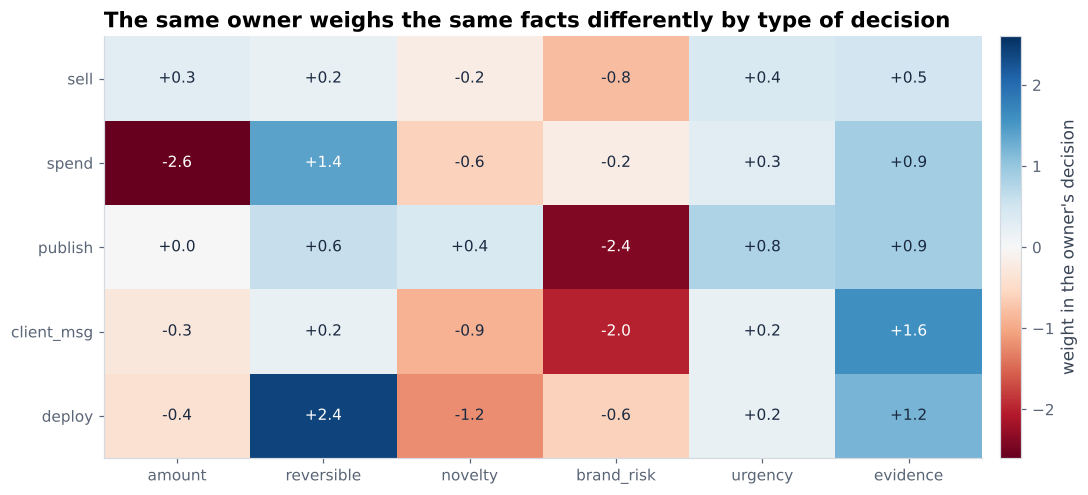

In [4]:
fig, ax = plt.subplots(figsize=(10, 4.6))
im = ax.imshow(W.values, cmap="RdBu", vmin=-2.6, vmax=2.6, aspect="auto")
ax.set_xticks(range(len(FEATURES))); ax.set_xticklabels(FEATURES)
ax.set_yticks(range(len(TYPES))); ax.set_yticklabels(TYPES); ax.grid(False)
for i in range(W.shape[0]):
    for j in range(W.shape[1]):
        ax.text(j, i, f"{W.values[i, j]:+.1f}", ha="center", va="center", fontsize=10,
                color="white" if abs(W.values[i, j]) > 1.3 else PALETTE["navy"])
fig.colorbar(im, ax=ax, fraction=0.03, pad=0.02, label="weight in the owner's decision")
ax.set_title("The same owner weighs the same facts differently by type of decision")
plt.tight_layout(); plt.show()

## 4. Experiment 1: one profile or one per decision type?

Four agents learn online over 120 days (40 decisions a day). Each asks the owner when its confidence max(p, 1−p) is below τ = 0.85 and learns from every answer.

1. **Fixed rules**: the rules I wrote once (approve sells; approve spending under a fixed amount; approve the rest when brand risk is low). No learning.
2. **One profile**: a single logistic model for all decisions, with the type as a feature.
3. **Profile per type**: one model per decision type.
4. **Per type + forgetting**: like 3, but recent decisions weigh more, so the profile follows the owner when he changes. On day 60 the owner's situation changes (debts paid: spending becomes less sensitive to amount).


In [5]:
def owner_at(day):
    """The owner evolves: after day 60 (debts paid) the amount matters less when spending."""
    if day < 60:
        return OWNER
    p = {k: dict(v) for k, v in OWNER.items()}
    p["spend"] = dict(w=[-1.0, 1.4, -0.6, -0.2, 0.3, 0.9], b=0.8)
    return p

def fixed_rule(k, x):
    if k == "sell": return 1
    if k == "spend": return int(x[0] < -0.3)
    return int(x[3] < 0.3)

class Agent:
    def __init__(self, mode, tau=0.85, half_life=None):
        self.mode, self.tau, self.half_life = mode, tau, half_life
        self.X, self.y, self.k, self.t = [], [], [], []
        self.models = {}
    def _design(self, k, x):
        if self.mode == "one_profile":
            return np.r_[x, [1.0 * (k == t) for t in TYPES]]
        return np.asarray(x)
    def refit(self, day):
        X, y, kk, t = map(np.array, (self.X, self.y, self.k, self.t)) if self.X else ([], [], [], [])
        if len(self.X) == 0: return
        wts = np.ones(len(y)) if not self.half_life else 0.5 ** ((day - t) / self.half_life)
        groups = {"all": np.ones(len(y), bool)} if self.mode == "one_profile" else {k: kk == k for k in TYPES}
        for g, m in groups.items():
            if m.sum() >= 8 and len(set(y[m])) == 2:
                self.models[g] = LogisticRegression(C=1.0).fit(X[m], y[m], sample_weight=wts[m])
    def predict(self, k, x):
        if self.mode == "fixed_rules":
            return float(fixed_rule(k, x))
        g = "all" if self.mode == "one_profile" else k
        if g not in self.models: return 0.5
        return self.models[g].predict_proba([self._design(k, x)])[0, 1]
    def learn(self, k, x, label, day):
        self.X.append(self._design(k, x)); self.y.append(label); self.k.append(k); self.t.append(day)

def run(agent, seed=0, days=120, per_day=40):
    rng = np.random.default_rng(seed); rows = []; last = -1
    for d, k, x in stream(rng, days, per_day):
        if d != last: agent.refit(d); last = d
        truth = decide(owner_at(d), k, x, rng)
        p = agent.predict(k, x)
        ask = agent.mode != "fixed_rules" and max(p, 1 - p) < agent.tau
        if ask:
            agent.learn(k, x, truth, d)
            rows.append(dict(day=d, type=k, asked=1, error=0))
        else:
            act = int(p > 0.5); err = int(act != truth)
            rows.append(dict(day=d, type=k, asked=0, error=err))
            if err and agent.mode != "fixed_rules":
                agent.learn(k, x, truth, d)          # the owner later corrects the mistake
    return pd.DataFrame(rows)

AGENTS = {"fixed rules": lambda: Agent("fixed_rules"), "one profile": lambda: Agent("one_profile"),
          "profile per type": lambda: Agent("per_type"), "per type + forgetting": lambda: Agent("per_type", half_life=15)}
runs = {name: pd.concat([run(make(), seed=s).assign(seed=s) for s in range(5)]) for name, make in AGENTS.items()}
summary = pd.DataFrame({name: dict(errors_per_100_decisions=100 * r.error.mean(), asks_per_100_decisions=100 * r.asked.mean(),
                                   errors_per_100_after_change=100 * r[r.day >= 60].error.mean())
                        for name, r in runs.items()}).T.round(1)
summary

,errors_per_100_decisions,asks_per_100_decisions,errors_per_100_after_change
fixed rules,24.5,0.0,25.9
one profile,1.1,56.6,0.9
profile per type,0.3,27.1,0.4
per type + forgetting,0.1,35.9,0.1


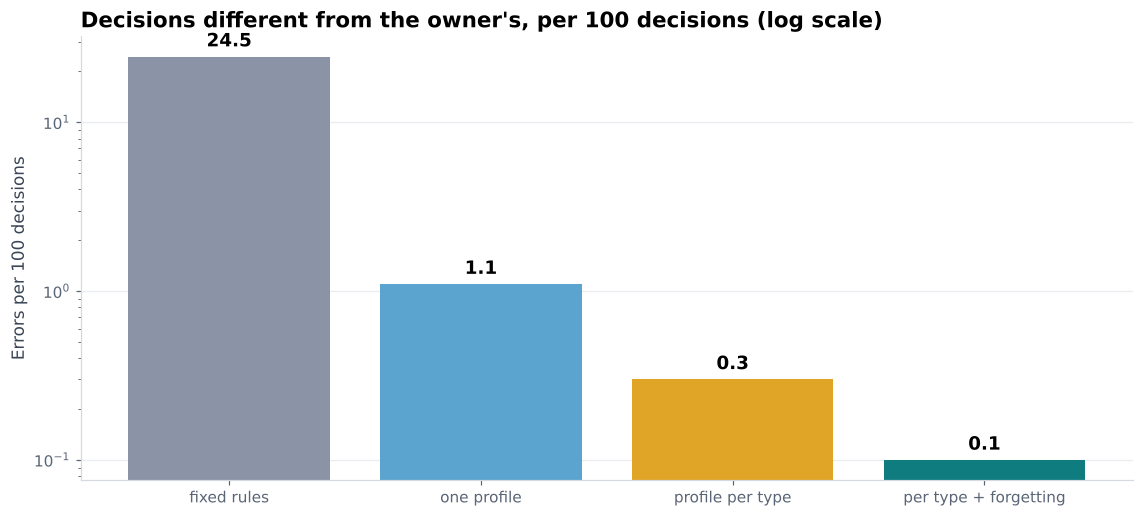

In [6]:
colors = [PALETTE["grey"], PALETTE["sky"], PALETTE["gold"], PALETTE["teal"]]
fig, ax = plt.subplots(figsize=(10.5, 4.8))
bars = ax.bar(summary.index, summary.errors_per_100_decisions, color=colors)
ax.set_yscale("log"); ax.grid(axis="x", visible=False)
for b_, v in zip(bars, summary.errors_per_100_decisions):
    ax.text(b_.get_x() + b_.get_width() / 2, v * 1.15, f"{v:.1f}", ha="center", fontsize=12, fontweight="bold")
ax.set_title("Decisions different from the owner's, per 100 decisions (log scale)")
ax.set_ylabel("Errors per 100 decisions")
plt.tight_layout(); plt.show()

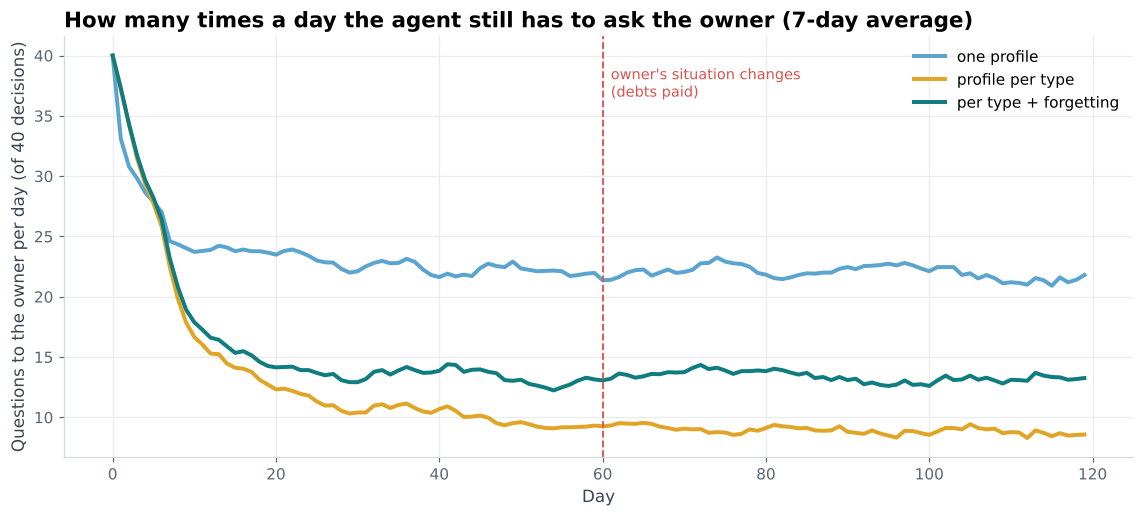

In [7]:
fig, ax = plt.subplots(figsize=(10.5, 4.8))
for (name, r), c in list(zip(runs.items(), colors))[1:]:
    s = r.groupby("day").asked.mean().rolling(7, min_periods=1).mean() * 40
    ax.plot(s.index, s.values, lw=2.6, color=c, label=name)
ax.axvline(60, color=PALETTE["coral"], ls="--", lw=1.2)
ax.text(61, ax.get_ylim()[1] * 0.88, "owner's situation changes\n(debts paid)", color=PALETTE["coral"], fontsize=9.5)
ax.set_title("How many times a day the agent still has to ask the owner (7-day average)")
ax.set_xlabel("Day"); ax.set_ylabel("Questions to the owner per day (of 40 decisions)"); ax.legend(loc="upper right")
plt.tight_layout(); plt.show()

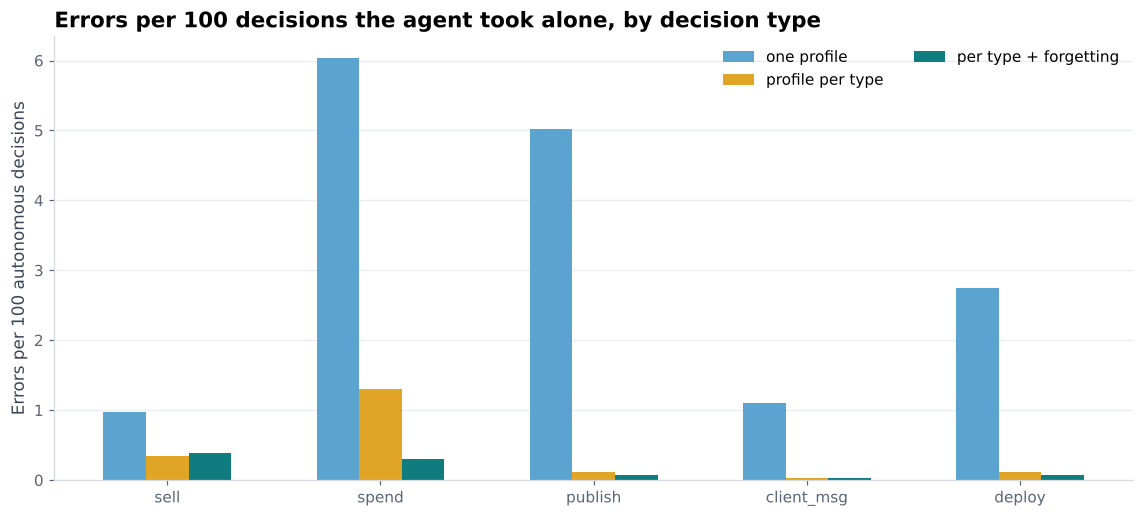

In [8]:
# Error by decision type: where does a single profile fail?
by_type = pd.DataFrame({name: r[r.asked == 0].groupby("type").error.mean() * 100 for name, r in runs.items() if name != "fixed rules"}).loc[TYPES]
fig, ax = plt.subplots(figsize=(10.5, 4.8))
xpos = np.arange(len(TYPES)); w = 0.2
for i, (name, c) in enumerate(zip(by_type.columns, colors[1:])):
    ax.bar(xpos + (i - 1) * w, by_type[name], w, color=c, label=name)
ax.set_xticks(xpos); ax.set_xticklabels(TYPES); ax.grid(axis="x", visible=False)
ax.set_title("Errors per 100 decisions the agent took alone, by decision type")
ax.set_ylabel("Errors per 100 autonomous decisions"); ax.legend(ncol=2)
plt.tight_layout(); plt.show()

## 5. Experiment 2: a specifier approves on the owner's behalf

From day 60, half of the approval requests are answered by a **specifier** whose situation is different (more permissive with money and brand risk). Two agents with a profile per type and forgetting:

- **Learns from whoever approves**: the specifier's answers become training labels, exactly like the owner's.
- **Owner-anchored**: the specifier's answer is recorded as a *comment*. If it agrees with the owner model, the agent proceeds; if it conflicts, the agent asks the owner and passes the specifier's comment along. Only the owner's answers train the owner profile.

The question is the thesis question: does the agent keep deciding **as the owner**?


In [9]:
def run_specifier(anchored, seed=0, days=120, per_day=40, tau=0.85):
    rng = np.random.default_rng(seed); ag = Agent("per_type", tau=tau, half_life=15); rows = []; last = -1
    for d, k, x in stream(rng, days, per_day):
        if d != last: ag.refit(d); last = d
        own = decide(OWNER, k, x, rng)
        p = ag.predict(k, x)
        if max(p, 1 - p) >= tau:
            rows.append(dict(day=d, error=int(int(p > 0.5) != own), owner_asked=0)); continue
        if d >= 60 and rng.random() < 0.5:                      # the specifier answers
            spec = decide(SPECIFIER, k, x, rng)
            if not anchored:
                ag.learn(k, x, spec, d)
                rows.append(dict(day=d, error=int(spec != own), owner_asked=0)); continue
            if spec == int(p > 0.5):                             # agrees with the owner model: proceed
                rows.append(dict(day=d, error=int(spec != own), owner_asked=0)); continue
        ag.learn(k, x, own, d)                                   # the owner answers (with the specifier's comment)
        rows.append(dict(day=d, error=0, owner_asked=1))
    return pd.DataFrame(rows)

spec = {lab: pd.concat([run_specifier(a, seed=s) for s in range(5)]) for lab, a in
        [("learns from whoever approves", False), ("owner-anchored", True)]}
pd.DataFrame({lab: dict(errors_per_100_after_day60=100 * r[r.day >= 60].error.mean(),
                        owner_questions_per_day_after_day60=r[r.day >= 60].owner_asked.sum() / (60 * 5))
              for lab, r in spec.items()}).T.round(2)

,errors_per_100_after_day60,owner_questions_per_day_after_day60
learns from whoever approves,9.12,7.62
owner-anchored,1.08,9.81


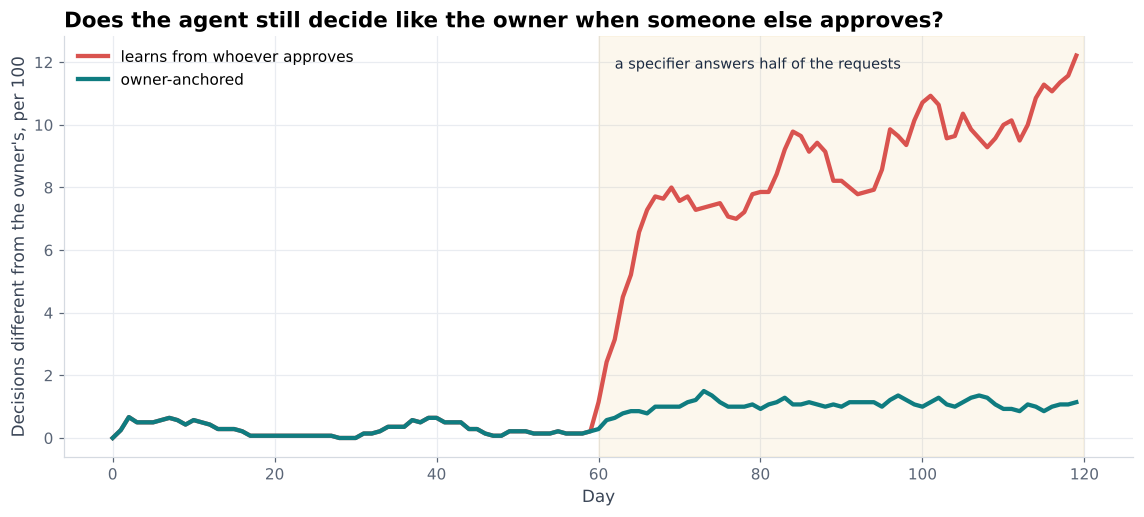

In [10]:
fig, ax = plt.subplots(figsize=(10.5, 4.8))
for (lab, r), c in zip(spec.items(), [PALETTE["coral"], PALETTE["teal"]]):
    s = r.groupby("day").error.mean().rolling(7, min_periods=1).mean() * 100
    ax.plot(s.index, s.values, lw=2.8, color=c, label=lab)
ax.axvspan(60, 120, color=PALETTE["gold"], alpha=0.08)
ax.text(62, ax.get_ylim()[1] * 0.92, "a specifier answers half of the requests", color=PALETTE["navy"], fontsize=9.5)
ax.set_title("Does the agent still decide like the owner when someone else approves?")
ax.set_xlabel("Day"); ax.set_ylabel("Decisions different from the owner's, per 100"); ax.legend(loc="upper left")
plt.tight_layout(); plt.show()

## 6. Findings

> **Key finding 1.** Learning **one profile per type of decision** makes about a third of the errors of a single profile (0.3 vs 1.1 per 100 decisions) while asking the owner **half as often** (27 vs 57 questions per 100). The single profile fails exactly where the owner's situation weighs most (spending and deploying), because it averages decision types the way standard RLHF averages people [2]. Fixed rules never ask, but about one decision in four differs from the owner's.
>
> **Key finding 2.** When the owner's situation changes, the agent that **forgets** old decisions keeps its errors lowest after the change, but asks more (36 vs 27 questions per 100): following an owner who evolves has a price in questions.
>
> **Key finding 3.** If the agent learns from whoever approves, the specifier's profile **silently replaces the owner's**: after day 60 about 9 decisions in 100 differ from the owner's, against about 1 in 100 when the specifier's answer is treated as a comment and the owner is asked only on conflicts. The cost is about 2 more questions a day. This is the mechanism behind what I lived: the rules were not lost, **the source of the labels changed**.

**Limitations:** linear owner, synthetic decisions, a fixed confidence threshold for asking (a learned rejector [5] is the next step), and the owner always available to answer.

## 7. How the next notebooks test the thesis

| Notebook | Decision type studied | What part of the question it tests |
|---|---|---|
| 02 · Equilibra | How much money to put at risk | A rule that depends on the owner's **economic situation**, transferred to users in other situations |
| 03 · Press | Whether to publish a piece | Learning from **corrections with reasons** versus yes/no approvals; the cost of waiting for approval |
| 04 · SEO | Which changes need approval | Autonomy by **reversibility**; owner rules learned in one project applied to all |
| 05 · Vending | What and when to restock | The owner's **time and distance limits** versus the "optimal" plan |
| 06 · GrabGo | Charge or ask, camera or phone | The owner's **privacy and cost** trade-off per location; rules applied to every user profile |
| 07 · Suppliers | Accept or reject a shipment | The owner's **tolerance per product**, measured from phone photos, videos and weight |

## References

1. Hadfield-Menell, D., Dragan, A., Abbeel, P., & Russell, S. (2016). *Cooperative Inverse Reinforcement Learning.* NeurIPS 2016. arXiv:1606.03137.
2. Poddar, S., Wan, Y., Ivison, H., Gupta, A., & Jaques, N. (2024). *Personalizing Reinforcement Learning from Human Feedback with Variational Preference Learning.* NeurIPS 2024. arXiv:2408.10075.
3. Kirk, H. R., et al. (2024). *The PRISM Alignment Dataset.* NeurIPS 2024 Datasets and Benchmarks. arXiv:2404.16019.
4. Park, J. S., Zou, C. Q., Shaw, A., Hill, B. M., Cai, C., Morris, M. R., Willer, R., Liang, P., & Bernstein, M. S. (2024). *Generative Agent Simulations of 1,000 People.* arXiv:2411.10109.
5. Mozannar, H., & Sontag, D. (2020). *Consistent Estimators for Learning to Defer to an Expert.* ICML 2020, PMLR 119:7076–7087.
6. Madras, D., Pitassi, T., & Zemel, R. (2018). *Predict Responsibly: Improving Fairness and Accuracy by Learning to Defer.* NeurIPS 2018.
7. Simon, H. A. (1955). *A behavioral model of rational choice.* Quarterly Journal of Economics, 69(1), 99–118.
8. Mullainathan, S., & Shafir, E. (2013). *Scarcity: Why Having Too Little Means So Much.* Times Books.
9. Gama, J., Žliobaitė, I., Bifet, A., Pechenizkiy, M., & Bouchachia, A. (2014). *A survey on concept drift adaptation.* ACM Computing Surveys, 46(4), 44.
